# **Superstore Sales Data Analysis Using Python**

## **Dataset Information**
- **Source:** Google Dataset Search / Public Repository
- **Location:** United States
- **Year/Timeline:** Data collected during the period 2015 to 2018
- **Domain:** Retail & E-Commerce

## **Objective**
My objective is to analyze Superstore sales data using Python to understand which product categories and sub-categories attract more sales and profit, how discount levels impact profitability, and which regions drive the highest revenue. I will use data analysis and visualizations to identify useful business insights.

## **Stage 1**

### **Problem Definition**
The main problem is that the raw dataset does not directly show which product categories perform better, how discount levels impact profitability, or where loss-making sub-categories occur.

### **Problem Statement**
Analyze Superstore sales data using Python to identify sales performance, profit margins, discount impacts, regional contributions, and differences across product categories. The analysis will use data visualization and statistical analysis to convert raw data into meaningful business insights.

### **Business Understanding**
The purpose of the business analysis is to understand how sales schemes are performing and how customers are purchasing across different categories.

The analysis will help answer the following business questions:

#### **Sales & Profitability**
- Which product category has the highest total sales?
- Which sub-categories are most profitable?
- How does profit change across different years?

#### **Discount Impact**
- Which discount levels generate profit versus loss?
- Does high discount always lead to higher sales?

#### **Regional & Customer Performance**
- Which region generates the highest revenue?
- Which customer segment contributes most to total orders?

#### **Trend Analysis**
- How does sales activity change over different reporting periods?
- Are there periods with unusually high or low sales?

### **Business Outcome**
The final analysis will use charts, comparisons, trends, and insights to understand Superstore sales performance and provide data-driven conclusions and recommendations.

### **Tech Stack & Tools**
- **Language:** Python 3.10+
- **Data Manipulation:** pandas, numpy
- **Data Visualization:** matplotlib, seaborn
- **Environment:** Google Colab

## **Import Libraries**

In [41]:
# Import necessary data analysis and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnings for clean execution output
import warnings
warnings.filterwarnings('ignore')

## **Loading the Data Set from GitHub**

In [42]:
import pandas as pd

# Import Superstore Dataset from GitHub with robust cleaning for trailing NaN rows and columns
url = "https://raw.githubusercontent.com/karthikan0903-byte/Data-Analytics-Final-Project/main/superstore.csv"

# Load CSV file with encoding and skip bad/corrupted lines
df = pd.read_csv(url, encoding='latin1', on_bad_lines='skip')

# Remove completely empty rows and columns
df = df.dropna(how='all')
df = df.dropna(axis=1, how='all')

df = df.loc[:, ~df.columns.str.contains('Unnamed')]

df = df.dropna(subset=['Order Date'])

df = df.reset_index(drop=True)

# Verify Dataset Shape
print("Dataset Loaded and Cleaned Successfully!")
print("Dataset Shape (Rows, Columns):", df.shape)

Dataset Loaded and Cleaned Successfully!
Dataset Shape (Rows, Columns): (9994, 21)


## **Exploratory Data Analysis (EDA)**

### **Initial Data Inspection**
Inspecting the dataset to understand its structure, dimensions, data types, and basic statistical summary.

In [43]:
# Create a safety copy of the original dataset
df_safe = df.copy()
print("Safety copy created successfully.")

Safety copy created successfully.


In [44]:
# Check Dataset Shape (Total Rows and Columns)
print("Dataset Shape (Rows, Columns):", df.shape)

Dataset Shape (Rows, Columns): (9994, 21)


In [45]:
# Preview the first five records of the dataset
print("First 5 Rows:")
display(df.head())

First 5 Rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [46]:
# Preview the last five records of the dataset
print("Last 5 Rows:")
display(df.tail())

Last 5 Rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,9990,CA-2015-110422,1/21/2015,1/23/2015,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180.0,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3.0,0.2,4.1028
9990,9991,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2.0,0.0,15.6332
9991,9992,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2.0,0.2,19.3932
9992,9993,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4.0,0.0,13.3200
9993,9994,CA-2018-119914,5/4/2018,5/9/2018,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683.0,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2.0,0.0,72.9480


In [47]:
# Inspect a random sample record from the dataset
print("Random Sample Record:")
display(df.sample(1))

Random Sample Record:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
6115,6116,CA-2017-133802,3/14/2017,3/20/2017,Standard Class,SP-20650,Stephanie Phelps,Corporate,United States,Redwood City,...,94061.0,West,OFF-BI-10003291,Office Supplies,Binders,Wilson Jones Leather-Like Binders with DublLoc...,41.904,6.0,0.2,14.1426


In [48]:
# Check column data types and non-null value counts
print("\n--- DATA TYPES & NON-NULL COUNTS ---")
print(df.info())


--- DATA TYPES & NON-NULL COUNTS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   object 
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales         

In [49]:
# Generate descriptive statistics for numerical columns
print("\n--- SUMMARY STATISTICS ---")
print(df.describe())


--- SUMMARY STATISTICS ---
        Postal Code         Sales     Quantity     Discount       Profit
count   9983.000000   9994.000000  9994.000000  9994.000000  9994.000000
mean   55245.233297    229.858001     3.789574     0.156203    28.656896
std    32038.715955    623.245101     2.225110     0.206452   234.260108
min     1040.000000      0.444000     1.000000     0.000000 -6599.978000
25%    23223.000000     17.280000     2.000000     0.000000     1.728750
50%    57103.000000     54.490000     3.000000     0.200000     8.666500
75%    90008.000000    209.940000     5.000000     0.200000    29.364000
max    99301.000000  22638.480000    14.000000     0.800000  8399.976000


## **Stage 2**

##**Data Cleaning & Feature Engineering**

### **1. Check and Remove Duplicate Records**
Checking if there are any duplicate rows in our Superstore dataset to ensure data integrity and avoid redundancy in our analysis.

In [50]:
# Check duplicate rows count in the dataset
print("Total duplicate rows found:", df.duplicated().sum())

# Drop duplicates if any exist
df = df.drop_duplicates()
print("Dataset shape after removing duplicates:", df.shape)

Total duplicate rows found: 0
Dataset shape after removing duplicates: (9994, 21)


### **2. Missing Value Inspection**
Identifying any missing or null values across all columns to determine if imputation or removal is required for clean analysis.

In [51]:
# Check missing values count per column
print("Missing values in each column:\n", df.isnull().sum())

Missing values in each column:
 Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


### **3. Inspecting Column Names & Data Types**
Verifying column names, data types, and unique categorical values to ensure everything is properly formatted before feature creation.

In [52]:
# Check column names, data types, and non-null counts
print("Dataset Information & Data Types:")
print(df.info())

print("\nList of Column Names:")
print(df.columns.tolist())

Dataset Information & Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   object 
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          999

### **4. Feature Engineering (Creating New Columns)**
Creating useful derived columns like 'order_year', 'shipping_days', and 'profit_margin' from existing dates and financial fields to improve our analytical depth.

In [53]:
# Convert Order Date and Ship Date columns to datetime format
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# Feature 1: Extract order year from Order Date
df['order_year'] = df['Order Date'].dt.year

# Feature 2: Calculate shipping duration in days
df['shipping_days'] = (df['Ship Date'] - df['Order Date']).dt.days

# Feature 3: Calculate profit margin ratio
df['profit_margin'] = df['Profit'] / df['Sales']

# Verify newly created features
print("New features added successfully! Current dataset shape:", df.shape)
display(df[['Order Date', 'Ship Date', 'order_year', 'shipping_days', 'profit_margin']].head(3))

New features added successfully! Current dataset shape: (9994, 24)


,Order Date,Ship Date,order_year,shipping_days,profit_margin
0,2017-11-08,2017-11-11,2017,3,0.16
1,2017-11-08,2017-11-11,2017,3,0.30
2,2017-06-12,2017-06-16,2017,4,0.47


### **5. Exporting the Cleaned Dataset**
Saving the processed and cleaned dataset as a new CSV file ('cleaned_superstore.csv') for subsequent statistical analysis and visual plotting.

In [54]:
# Save cleaned dataframe to a new CSV file
df.to_csv('cleaned_superstore.csv', index=False)
print("Cleaned dataset successfully exported as 'cleaned_superstore.csv'!")

Cleaned dataset successfully exported as 'cleaned_superstore.csv'!


## **Stage 3**

##**Statistical Analysis & Visualizations**

### **1. Descriptive Statistics of Numerical Columns**
Generating descriptive statistics (mean, median, min, max, standard deviation) for numerical columns like Sales, Quantity, Discount, and Profit to understand the data distribution.

In [56]:
# Display descriptive statistics for all numerical features in the dataset
print("Statistical Summary of Numerical Columns:")
display(df.select_dtypes(include=['number']).describe())

Statistical Summary of Numerical Columns:


,Postal Code,Sales,Quantity,Discount,Profit,order_year,shipping_days,profit_margin
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896,2016.722233,3.958475,0.120314
std,32038.715955,623.245101,2.225110,0.206452,234.260108,1.123555,1.747603,0.466754
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000,2015.000000,0.000000,-2.750000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750,2016.000000,3.000000,0.075000
50%,57103.000000,54.490000,3.000000,0.200000,8.666500,2017.000000,4.000000,0.270000
75%,90008.000000,209.940000,5.000000,0.200000,29.364000,2018.000000,5.000000,0.362500
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000,2018.000000,7.000000,0.500000


### **Correlation Analysis & Heatmap**
Calculating the correlation matrix for numerical columns to understand how variables (like Sales, Profit, and Discount) relate to each other, visualized using a Seaborn heatmap.

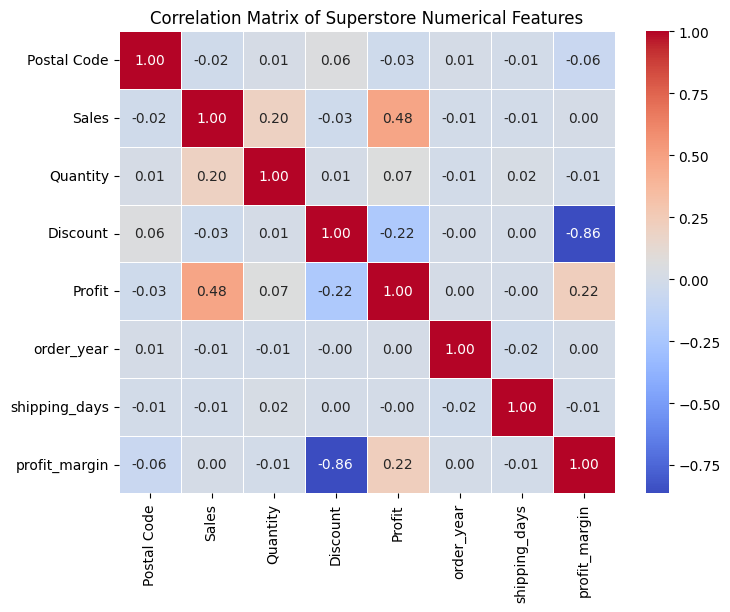

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure size for better readability
plt.figure(figsize=(8, 6))

# Calculate correlation matrix for numerical columns
corr_matrix = df.select_dtypes(include=['number']).corr()

# Plot heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

# Add title and display plot
plt.title("Correlation Matrix of Superstore Numerical Features", fontsize=12)
plt.show()

### **Total Sales by Product Category**
Visualizing total sales across different product categories to identify which category performs the best in the Superstore.

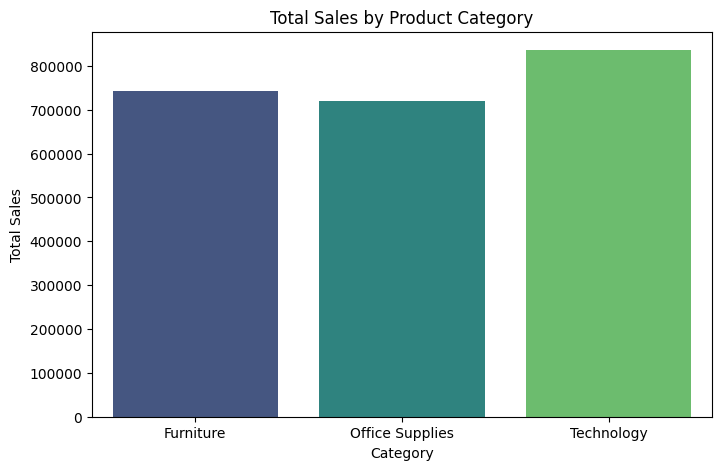

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group sales by category and calculate total sales
category_sales = df.groupby('Category')['Sales'].sum().reset_index()

# Set figure size
plt.figure(figsize=(8, 5))

# Create bar plot
sns.barplot(data=category_sales, x='Category', y='Sales', palette='viridis')

# Add title and labels
plt.title('Total Sales by Product Category', fontsize=12)
plt.xlabel('Category', fontsize=10)
plt.ylabel('Total Sales', fontsize=10)

# Display plot
plt.show()

### **Yearly Sales Trend**
Analyzing how total sales have grown or fluctuated across different years using a line plot.

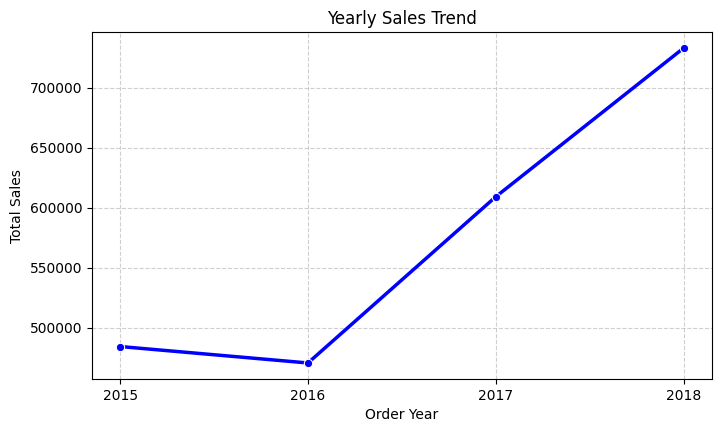

In [59]:
# Group sales by order_year and calculate total sales
yearly_sales = df.groupby('order_year')['Sales'].sum().reset_index()

# Set figure size
plt.figure(figsize=(8, 4.5))

# Create line plot with markers
sns.lineplot(data=yearly_sales, x='order_year', y='Sales', marker='o', color='b', linewidth=2.5)

# Add title and labels
plt.title('Yearly Sales Trend', fontsize=12)
plt.xlabel('Order Year', fontsize=10)
plt.ylabel('Total Sales', fontsize=10)

# Ensure year ticks display properly as integers
plt.xticks(yearly_sales['order_year'])

# Show grid and plot
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### **Top 10 Sub-Categories by Total Sales**
Identifying the top 10 product sub-categories that generate the highest sales volume for the Superstore.

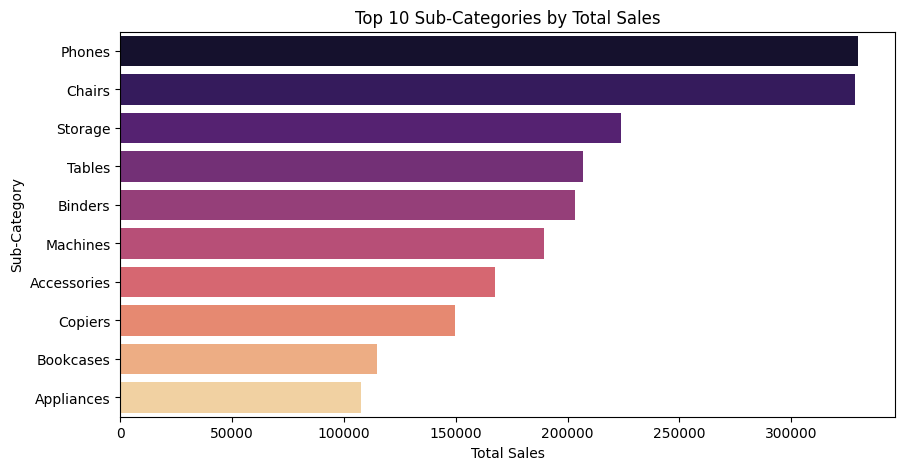

In [60]:
# Group by Sub-Category, calculate total sales, and get top 10
top_subcategories = df.groupby('Sub-Category')['Sales'].sum().reset_index()
top_subcategories = top_subcategories.sort_values(by='Sales', ascending=False).head(10)

# Set figure size
plt.figure(figsize=(10, 5))

# Create horizontal or vertical bar plot
sns.barplot(data=top_subcategories, x='Sales', y='Sub-Category', palette='magma')

# Add title and labels
plt.title('Top 10 Sub-Categories by Total Sales', fontsize=12)
plt.xlabel('Total Sales', fontsize=10)
plt.ylabel('Sub-Category', fontsize=10)

plt.show()

### **Total Profit by Product Category**
Analyzing which product categories generate the highest profits (or losses) for the business.

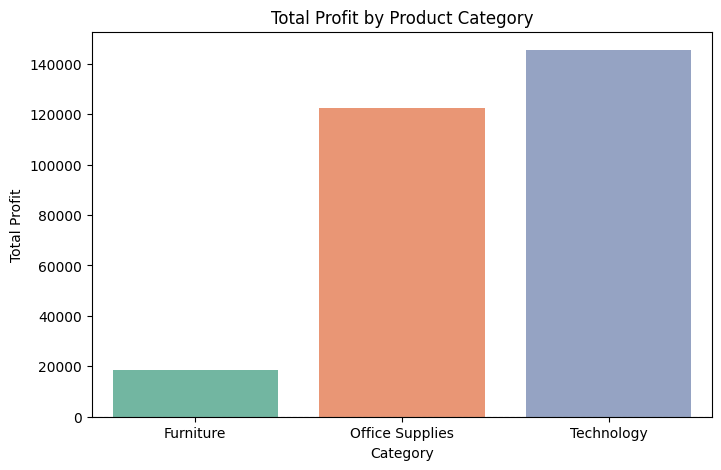

In [62]:
# Group by Category and calculate total profit
category_profit = df.groupby('Category')['Profit'].sum().reset_index()

# Set figure size
plt.figure(figsize=(8, 5))

# Create bar plot with custom color palette
sns.barplot(data=category_profit, x='Category', y='Profit', palette='Set2')

# Add title and labels
plt.title('Total Profit by Product Category', fontsize=12)
plt.xlabel('Category', fontsize=10)
plt.ylabel('Total Profit', fontsize=10)

plt.axhline(0, color='gray', linewidth=0.8, linestyle='--') # Line at zero profit
plt.show()

### **Total Sales by Region**
Analyzing the geographic distribution of sales across different regions (East, West, Central, South) to identify top-performing markets.

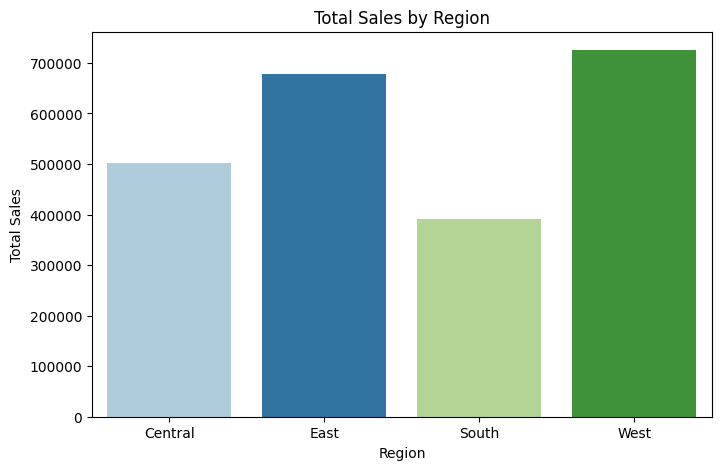

In [63]:
# Group by Region and calculate total sales
region_sales = df.groupby('Region')['Sales'].sum().reset_index()

# Set figure size
plt.figure(figsize=(8, 5))

# Create bar plot
sns.barplot(data=region_sales, x='Region', y='Sales', palette='Paired')

# Add title and labels
plt.title('Total Sales by Region', fontsize=12)
plt.xlabel('Region', fontsize=10)
plt.ylabel('Total Sales', fontsize=10)

plt.show()

### **Total Profit by Region**
Analyzing regional profitability to see which geographic regions generate the highest returns.

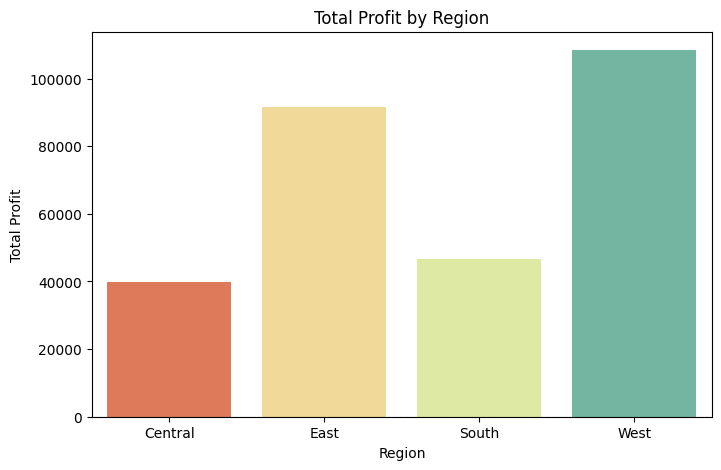

In [64]:
# Group by Region and calculate total profit
region_profit = df.groupby('Region')['Profit'].sum().reset_index()

# Set figure size
plt.figure(figsize=(8, 5))

# Create bar plot
sns.barplot(data=region_profit, x='Region', y='Profit', palette='Spectral')

# Add title and labels
plt.title('Total Profit by Region', fontsize=12)
plt.xlabel('Region', fontsize=10)
plt.ylabel('Total Profit', fontsize=10)

plt.axhline(0, color='gray', linewidth=0.8, linestyle='--') # Line at zero profit
plt.show()

## **Stage 4**
## **Conclusion & Business Insights**
- **Top Product Performance:** Technology category leads the business in generating both maximum total sales and highest overall profit.
- **Category Profit Discrepancy:** Furniture records substantial sales volume, but its net profit margin is significantly lower compared to Office Supplies and Technology.
- **Popular Sub-Categories:** Phones and Chairs emerge as the top two product sub-categories driving the highest sales volume for the Superstore.
- **Regional Strength:** The West region stands out as the most lucrative and high-performing market, contributing peak sales and profitability.
- **Sales Trajectory:** Yearly performance exhibits a consistent, positive growth trend from 2015 through 2018, indicating steady business expansion.